# 24 Summarization

Meringkas teks panjang. Contoh: artikel berita IndoSum, dengan metode ekstraktif dan abstraktif.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

ISI_SETELAH_EDA

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal meminta ringkasan, dan metriknya biasanya ROUGE. Untuk merangkum ribuan komentar MBG, jalankan
per topik: pakai folder `01` dulu, lalu ringkas tiap topik.

**Yang perlu diganti kalau datanya beda:**
- `load_indosum` dan kolom `sentences`, `summary_text`.
- `SUMMARY_SENTENCES`, sesuaikan panjang ringkasan dengan jawaban.
- Tanpa `labels` per kalimat, lewati model ekstraktif supervised.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya metode ekstraktif, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
SUMMARY_SENTENCES = 3

SETTINGS = {
    "cepat": {
        "n_train": 2000,
        "n_dev": 150,
        "n_test": 300,
        "finetune_rows": 0,
        "finetune_epochs": 0,
    },
    "penuh": {
        "n_train": 4000,
        "n_dev": 300,
        "n_test": 1000,
        "finetune_rows": 3000,
        "finetune_epochs": 2,
    },
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'n_train': 4000, 'n_dev': 300, 'n_test': 1000, 'finetune_rows': 3000, 'finetune_epochs': 2}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Pembaca IndoSum.** Tiap artikel berupa paragraf, kalimat, dan token. `load_indosum` meratakannya menjadi
daftar kalimat, ringkasan, dan penanda kalimat mana yang masuk ringkasan.

In [6]:
def load_indosum(file_name: str, n_rows: int) -> pd.DataFrame:
    frame = pd.read_json(find_file(file_name), lines=True).head(n_rows)

    def flatten(paragraphs) -> list[str]:
        return [" ".join(tokens) for paragraph in paragraphs for tokens in paragraph]

    frame["sentences"] = frame["paragraphs"].map(flatten)
    frame["article"] = frame["sentences"].map(" ".join)
    frame["summary_text"] = frame["summary"].map(lambda s: " ".join(" ".join(t) for t in s))
    frame["first_summary"] = frame["summary"].map(lambda s: " ".join(s[0]) if len(s) else "")
    frame["labels"] = frame["gold_labels"].map(
        lambda g: [flag for paragraph in g for flag in paragraph]
    )
    return frame[["category", "sentences", "article", "summary_text", "first_summary", "labels"]]

**Seq2seq.** `generate_texts` menghasilkan teks dari model pretrained. `finetune_seq2seq` melatih model
itu pada data lu sendiri. Bobot akhir tidak disimpan, supaya folder hasil tetap kecil.

In [7]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer as SeqTokenizer  # noqa: E402


def load_seq2seq(name: str):
    tokenizer = SeqTokenizer.from_pretrained(MODEL_DIR / name)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_DIR / name).to(DEVICE)
    return tokenizer, model


@torch.inference_mode()
def generate_texts(
    model, tokenizer, texts, max_input=256, max_new=64, beams=4, batch_size=32, prefix=""
):
    """Hasilkan teks, urut dari yang terpanjang supaya padding lebih hemat."""
    model.eval()
    order = np.argsort([-len(t) for t in texts])
    outputs = [""] * len(texts)
    for start in range(0, len(texts), batch_size):
        picks = order[start : start + batch_size]
        tokens = tokenizer(
            [prefix + texts[i] for i in picks],
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_input,
        ).to(DEVICE)
        generated = model.generate(
            **tokens, max_new_tokens=max_new, num_beams=beams, no_repeat_ngram_size=3
        )
        decoded = tokenizer.batch_decode(generated, skip_special_tokens=True)
        for i, text in zip(picks, decoded):
            outputs[i] = text.strip()
    return outputs


def finetune_seq2seq(
    model,
    tokenizer,
    sources,
    targets,
    epochs,
    seed,
    lr=3e-5,
    batch_size=16,
    max_input=256,
    max_target=96,
    prefix="",
):
    """Latih model seq2seq dengan loss bawaan."""
    seed_everything(seed)
    source_tokens = tokenizer(
        [prefix + s for s in sources],
        truncation=True,
        max_length=max_input,
        padding="max_length",
        return_tensors="pt",
    )
    target_ids = tokenizer(
        text_target=list(targets),
        truncation=True,
        max_length=max_target,
        padding="max_length",
        return_tensors="pt",
    )["input_ids"]
    target_ids[target_ids == tokenizer.pad_token_id] = -100
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    generator = np.random.default_rng(seed)
    torch.cuda.empty_cache()
    model.train()
    for _ in range(epochs):
        order = generator.permutation(len(sources))
        for start in range(0, len(order), batch_size):
            pick = torch.as_tensor(order[start : start + batch_size])
            optimizer.zero_grad(set_to_none=True)
            # Potong padding per batch: logit mT5 sangat besar karena kosakatanya 250 ribu.
            attention = source_tokens["attention_mask"][pick]
            source_len = int(attention.sum(1).max())
            target_len = int((target_ids[pick] != -100).sum(1).max())
            loss = model(
                input_ids=source_tokens["input_ids"][pick][:, :source_len].to(DEVICE),
                attention_mask=attention[:, :source_len].to(DEVICE),
                labels=target_ids[pick][:, :target_len].to(DEVICE),
            ).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
    return model

## 4. EDA

Muat latih dan test. File `train.01` dan `test.01` adalah pembagian resmi IndoSum.

In [8]:
train = load_indosum("train.01.jsonl", SETTINGS["n_train"])
test = load_indosum("test.01.jsonl", SETTINGS["n_test"])
dev = load_indosum("dev.01.jsonl", SETTINGS["n_dev"])
print(f"latih={len(train)} | dev={len(dev)} | test={len(test)}")
stats = pd.DataFrame(
    {
        "kalimat_artikel": train["sentences"].str.len(),
        "kata_artikel": train["article"].str.split().str.len(),
        "kata_ringkasan": train["summary_text"].str.split().str.len(),
        "kalimat_terpilih": train["labels"].map(sum),
    }
)
stats.describe(percentiles=[0.5, 0.95]).loc[["50%", "95%", "max"]].round(0)

latih=4000 | dev=300 | test=1000


,kalimat_artikel,kata_artikel,kata_ringkasan,kalimat_terpilih
50%,17.0,324.0,67.0,3.0
95%,35.0,603.0,78.0,5.0
max,75.0,1328.0,121.0,12.0


Posisi kalimat yang masuk ringkasan. Kalau menumpuk di awal, metode ambil kalimat pertama sudah kuat.

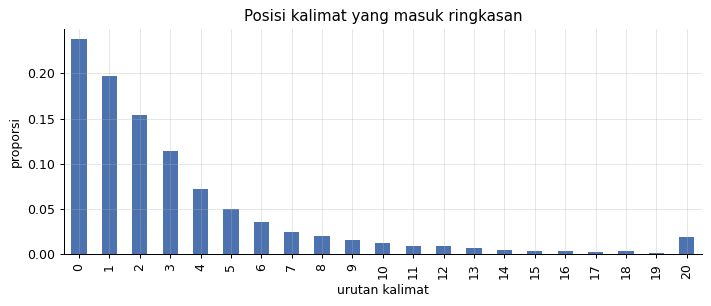

In [9]:
positions = [i for labels in train["labels"] for i, flag in enumerate(labels) if flag]
fig, ax = plt.subplots()
pd.Series(positions).clip(upper=20).value_counts(normalize=True).sort_index().plot.bar(
    ax=ax, color="#4C72B0"
)
ax.set(title="Posisi kalimat yang masuk ringkasan", xlabel="urutan kalimat", ylabel="proporsi")
plt.tight_layout()
plt.show()

**Temuan dan keputusan**

ISI_SETELAH_EDA

## 5. Preprocessing

Teks IndoSum sudah bersih, jadi hanya dirapikan. Sumber berita di awal artikel, seperti `Jakarta , CNN Indonesia - -`,
dibuang karena tidak ada di ringkasan.

In [10]:
SOURCE_RE = re.compile(r"^[\w ,.()]{0,50}?\s-\s(-\s)?")


def clean_sentence(sentence: str, index: int) -> str:
    return SOURCE_RE.sub("", sentence).strip() if index == 0 else sentence.strip()


def clean_sentences(sentences: list[str]) -> list[str]:
    return [clean_sentence(s, i) for i, s in enumerate(sentences)]


for frame in (train, dev, test):
    frame["sentences"] = frame["sentences"].map(clean_sentences)
    frame["article"] = frame["sentences"].map(" ".join)
print(train["sentences"][0][0][:120])

Dokter Ryan Thamrin , yang terkenal lewat acara Dokter Oz Indonesia , meninggal dunia pada Jumat ( 4 / 8 ) dini hari .


## 6. Validasi

Memakai pembagian resmi IndoSum: dev untuk memilih metode, test hanya untuk laporan. ROUGE ditulis sendiri supaya jalan offline: F1 unigram (ROUGE-1) dan bigram
(ROUGE-2) setelah huruf kecil dan tanpa tanda baca. Angkanya bisa sedikit berbeda dari paket ROUGE lain.

In [11]:
from collections import Counter  # noqa: E402

WORD_RE = re.compile(r"\w+")


def rouge_n(prediction: str, reference: str, n: int) -> float:
    def grams(text: str) -> Counter:
        words = WORD_RE.findall(text.lower())
        return Counter(tuple(words[i : i + n]) for i in range(len(words) - n + 1))

    pred, ref = grams(prediction), grams(reference)
    overlap = sum((pred & ref).values())
    if not overlap:
        return 0.0
    precision, recall = overlap / sum(pred.values()), overlap / sum(ref.values())
    return 2 * precision * recall / (precision + recall)


assert rouge_n("a b c", "a b c", 1) == 1.0 and rouge_n("a b", "c d", 2) == 0.0
assert abs(rouge_n("a b", "a c", 1) - 0.5) < 1e-9
references = test["summary_text"].tolist()
results: list[dict] = []


def record(name: str, summaries: list[str]) -> None:
    results.append(
        {
            "metode": name,
            "rouge1": round(np.mean([rouge_n(p, r, 1) for p, r in zip(summaries, references)]), 4),
            "rouge2": round(np.mean([rouge_n(p, r, 2) for p, r in zip(summaries, references)]), 4),
            "kata_rata2": round(np.mean([len(s.split()) for s in summaries]), 1),
        }
    )
    print(results[-1])

## 7. Baseline

Ambil beberapa kalimat pertama, yang sering sulit dikalahkan pada berita. Lalu TextRank tanpa pelatihan, yaitu
kalimat yang paling mirip dengan kalimat lain dianggap paling penting.

In [12]:
def lead_summary(sentences: list[str]) -> str:
    return " ".join(sentences[:SUMMARY_SENTENCES])


def textrank_summary(sentences: list[str]) -> str:
    if len(sentences) <= SUMMARY_SENTENCES:
        return " ".join(sentences)
    matrix = TfidfVectorizer().fit_transform(sentences)
    similarity = (matrix @ matrix.T).toarray()
    np.fill_diagonal(similarity, 0)
    transition = similarity / np.maximum(similarity.sum(1, keepdims=True), 1e-9)
    rank = np.ones(len(sentences)) / len(sentences)
    for _ in range(30):
        rank = 0.15 / len(sentences) + 0.85 * transition.T @ rank
    chosen = sorted(np.argsort(-rank)[:SUMMARY_SENTENCES])
    return " ".join(sentences[i] for i in chosen)


record("kalimat_pertama", [lead_summary(s) for s in test["sentences"]])
with stage("textrank"):
    record("textrank", [textrank_summary(s) for s in test["sentences"]])

{'metode': 'kalimat_pertama', 'rouge1': np.float64(0.6661), 'rouge2': np.float64(0.5976), 'kata_rata2': np.float64(66.6)}


{'metode': 'textrank', 'rouge1': np.float64(0.4316), 'rouge2': np.float64(0.2929), 'kata_rata2': np.float64(72.1)}
[waktu] textrank: 2 detik


## 8. Model Utama

**Ekstraktif supervised:** classifier per kalimat dari fitur posisi dan kemiripan, dilatih dari label kalimat.
**Abstraktif:** mT5 menulis ringkasan dengan kata sendiri. Di mode penuh mT5 disetel lagi pada data ini.

In [13]:
def sentence_features(sentences: list[str]) -> np.ndarray:
    matrix = TfidfVectorizer().fit_transform(sentences)
    centroid = np.asarray(matrix.mean(0)).ravel()
    similarity = matrix @ centroid
    total = len(sentences)
    return np.column_stack(
        [
            np.arange(total),
            np.arange(total) / total,
            similarity,
            [len(s.split()) for s in sentences],
            [float(i == 0) for i in range(total)],
            [float(i == 1) for i in range(total)],
        ]
    )


with stage("ekstraktif"):
    x_rows, y_rows = [], []
    for sentences, labels in zip(train["sentences"], train["labels"]):
        if len(sentences) == len(labels) and len(sentences) > 1:
            x_rows.append(sentence_features(sentences))
            y_rows.extend(labels)
    sentence_model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(
        np.vstack(x_rows), np.array(y_rows, dtype=int)
    )


def extractive_summary(sentences: list[str]) -> str:
    if len(sentences) <= SUMMARY_SENTENCES:
        return " ".join(sentences)
    scores = sentence_model.predict_proba(sentence_features(sentences))[:, 1]
    return " ".join(sentences[i] for i in sorted(np.argsort(-scores)[:SUMMARY_SENTENCES]))


record("ekstraktif_supervised", [extractive_summary(s) for s in test["sentences"]])

[waktu] ekstraktif: 8 detik


{'metode': 'ekstraktif_supervised', 'rouge1': np.float64(0.6676), 'rouge2': np.float64(0.5981), 'kata_rata2': np.float64(65.2)}


Ringkasan abstraktif. Untuk `csebuetnlp/mT5_multilingual_XLSum`, teks masukan dipotong sesuai batas model.

In [14]:
abstractive = None
if USE_PRETRAINED:
    tokenizer, model = load_seq2seq("mt5_sum")
    with stage("mt5_generate"):
        abstractive = generate_texts(
            model, tokenizer, test["article"].tolist(), max_input=512, max_new=128, batch_size=16
        )
    record("mt5_pretrained", abstractive)
    if SETTINGS["finetune_rows"]:
        with stage("mt5_finetune"):
            subset = train.head(SETTINGS["finetune_rows"])
            model = finetune_seq2seq(
                model,
                tokenizer,
                subset["article"].tolist(),
                subset["summary_text"].tolist(),
                SETTINGS["finetune_epochs"],
                SEED,
                batch_size=4,
                max_input=384,
                max_target=128,
            )
            abstractive = generate_texts(
                model,
                tokenizer,
                test["article"].tolist(),
                max_input=512,
                max_new=128,
                batch_size=16,
            )
        record("mt5_setelah_finetune", abstractive)
    with stage("mt5_dev"):
        abstractive_dev = generate_texts(
            model, tokenizer, dev["article"].tolist(), max_input=512, max_new=128, batch_size=16
        )
    del model
    torch.cuda.empty_cache()

[waktu] mt5_generate: 441 detik
{'metode': 'mt5_pretrained', 'rouge1': np.float64(0.3788), 'rouge2': np.float64(0.3156), 'kata_rata2': np.float64(21.6)}


[waktu] mt5_finetune: 2316 detik
{'metode': 'mt5_setelah_finetune', 'rouge1': np.float64(0.6721), 'rouge2': np.float64(0.5871), 'kata_rata2': np.float64(65.7)}


[waktu] mt5_dev: 242 detik


## 9. Post-processing

Pilih metode dengan ROUGE-2 tertinggi di **data dev**, bukan di test. Lalu rapikan: buang kalimat berulang di hasil.

In [15]:
def drop_repeats(summary: str) -> str:
    parts = re.split(r"(?<=[.!?])\s+", summary)
    return " ".join(dict.fromkeys(parts))


METHODS = {
    "ekstraktif_supervised": extractive_summary,
    "kalimat_pertama": lead_summary,
    "textrank": textrank_summary,
}
dev_outputs = {name: [fn(s) for s in dev["sentences"]] for name, fn in METHODS.items()}
test_outputs = {name: [fn(s) for s in test["sentences"]] for name, fn in METHODS.items()}
if abstractive is not None:
    dev_outputs["mt5"], test_outputs["mt5"] = abstractive_dev, abstractive

dev_scores = {
    name: round(float(np.mean([rouge_n(p, r, 2) for p, r in zip(out, dev["summary_text"])])), 4)
    for name, out in dev_outputs.items()
}
best_name = max(dev_scores, key=dev_scores.get)
print("ROUGE-2 dev:", dev_scores, "-> dipilih:", best_name)
final_summaries = [drop_repeats(s) for s in test_outputs[best_name]]
record(f"final_{best_name}", final_summaries)

ROUGE-2 dev: {'ekstraktif_supervised': 0.5963, 'kalimat_pertama': 0.5945, 'textrank': 0.3008, 'mt5': 0.5855} -> dipilih: ekstraktif_supervised
{'metode': 'final_ekstraktif_supervised', 'rouge1': np.float64(0.6676), 'rouge2': np.float64(0.5981), 'kata_rata2': np.float64(65.2)}


## 10. Post-analysis

**Tabel perbandingan.**

In [16]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,metode,rouge1,rouge2,kata_rata2
0,kalimat_pertama,0.6661,0.5976,66.6
1,textrank,0.4316,0.2929,72.1
2,ekstraktif_supervised,0.6676,0.5981,65.2
3,mt5_pretrained,0.3788,0.3156,21.6
4,mt5_setelah_finetune,0.6721,0.5871,65.7
5,final_ekstraktif_supervised,0.6676,0.5981,65.2


**Skor per kategori** dan contoh hasil. ROUGE tidak bisa menilai kebenaran fakta, jadi periksa ringkasan abstraktif
secara manual untuk fakta yang dikarang.

In [17]:
per_doc = pd.DataFrame(
    {
        "kategori": test["category"],
        "rouge2": [rouge_n(p, r, 2) for p, r in zip(final_summaries, references)],
    }
)
print(per_doc.groupby("kategori")["rouge2"].agg(["size", "mean"]).round(3))
examples = pd.DataFrame(
    {"asli": [r[:130] for r in references[:3]], "hasil": [p[:130] for p in final_summaries[:3]]}
)
examples

             size   mean
kategori                
hiburan        93  0.441
inspirasi       7  0.560
olahraga      263  0.667
showbiz       128  0.625
tajuk utama   385  0.634
teknologi     124  0.435


,asli,hasil
0,Eman Ahmed Abd El Aty memiliki berat badan mencapai 500 kilogram sebelum menjalankan o...,"Dilansir AFP , seorang warga Mesir yang dipercaya sebagai wanita terberat di dunia mas..."
1,Menteri Pertahanan Ryamizard Ryacudu menyambut baik usulan pembelian drone dari China ...,Menteri Pertahanan Ryamizard Ryacudu menyambut baik usulan pembelian drone dari China ...
2,"Rumah produksi film yang dibintangi Lindsay Lohan , Rachel McAdams dan Amanda Seyfried...","Meski sudah hampir 12 tahun berlalu , film Mean Girls merupakan salah satu film remaja..."


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [18]:
pd.DataFrame({"id": test.index, "ringkasan": final_summaries}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
run_summary(
    "summarization",
    len(train),
    {r["metode"]: {"rouge1": r["rouge1"], "rouge2": r["rouge2"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=summarization mode=penuh n_rows=4000 total_detik=3678 gpu=True
{
 "kalimat_pertama": {
  "rouge1": 0.6661,
  "rouge2": 0.5976
 },
 "textrank": {
  "rouge1": 0.4316,
  "rouge2": 0.2929
 },
 "ekstraktif_supervised": {
  "rouge1": 0.6676,
  "rouge2": 0.5981
 },
 "mt5_pretrained": {
  "rouge1": 0.3788,
  "rouge2": 0.3156
 },
 "mt5_setelah_finetune": {
  "rouge1": 0.6721,
  "rouge2": 0.5871
 },
 "final_ekstraktif_supervised": {
  "rouge1": 0.6676,
  "rouge2": 0.5981
 }
}


**Poin untuk presentasi**

ISI_SETELAH_EDA